# B8 – Phát Hiện Tấn Công Trong Hệ Thống ICS Bằng Support Vector Machine (SVM)
## Dữ Liệu Cảm Biến – Dataset BATADAL

## 1. Import Thư Viện

In [1]:
# ── Thư viện cơ bản ──────────────────────────────────────────────────────────
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ── scikit-learn ─────────────────────────────────────────────────────────────
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, brier_score_loss,
                             classification_report, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score,
                             roc_curve)
from sklearn.model_selection import (StratifiedKFold, cross_val_score,
                                     train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, LinearSVC

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 100

print("✅ Import xong!")
print("   Bài này chỉ dùng scikit-learn — không cần TensorFlow/PyTorch/GPU.")


✅ Import xong!
   Bài này chỉ dùng scikit-learn — không cần TensorFlow/PyTorch/GPU.


## 2. Cấu Hình Đường Dẫn & Tham Số

In [2]:
# ════════════════════════════════════════════════════════════════════
#  CẤU HÌNH
# ════════════════════════════════════════════════════════════════════
# ==========================
# ĐƯỜNG DẪN DATASET
# ==========================
BASE = Path("data/BATADAL")
for _cand in [BASE, Path.cwd().parent / "B7" / "data" / "BATADAL",
              Path.cwd().parent / "B6" / "data" / "BATADAL",
              Path.cwd().parent / "B1" / "data" / "BATADAL"]:
    if (_cand / "test_dataset_1.csv").exists():
        BASE = _cand
        break

# ==========================
# NHÃN (LABELS)
# ==========================
LABEL_COL = "ATT_FLAG"              # 0 = bình thường, khác 0 = bị tấn công
TARGET_NAMES = ["Bình thường", "Tấn công"]
META_COLS = ["DATETIME"]

# ==========================
# CHIA DỮ LIỆU & TÁI LẬP
# ==========================
SEED = 42          # seed cố định để kết quả tái lập được
TEST_SIZE = 0.3    # 70% train / 30% test
CV_FOLDS = 5       # số fold của cross-validation

# ==========================
# KHÔNG GIAN SIÊU THAM SỐ SVM
# ==========================
# C      : tham số điều chuẩn. C nhỏ → biên rộng, chấp nhận nhiều lỗi
#          huấn luyện (dễ underfit). C lớn → biên hẹp, bám sát dữ liệu
#          (dễ overfit).
# gamma  : bán kính ảnh hưởng của mỗi support vector trong kernel RBF.
#          'scale' là mặc định của sklearn, bằng 1/(n_features × var(X)).
# Hai tham số này TƯƠNG TÁC với nhau nên phải dò theo lưới hai chiều.
C_GRID = [0.01, 0.1, 1.0, 10.0, 100.0]
GAMMA_GRID = ["scale", 0.001, 0.01, 0.1, 1.0]

# GRID_N: cỡ tập con dùng để dò siêu tham số ở các phần A2–A4. SVM đắt theo
# bình phương số mẫu nên dò lưới trên toàn bộ tập train là không khả thi;
# mô hình cuối ở A8 mới huấn luyện lại trên toàn bộ tập train.
GRID_N = 5000

# MAX_ITER: chặn trên số vòng lặp của libsvm. Mặc định của sklearn là -1,
# tức KHÔNG giới hạn — trên dữ liệu không phân tách tuyến tính được,
# SVC(kernel='linear') có thể chạy hàng chục phút mà vẫn chưa hội tụ.
MAX_ITER = 200000

# ==========================
# NHẬN XÉT IN KÈM TỪNG PHẦN
# ==========================
KERNEL_COMMENT = (
    "\nNhận xét: ở C=1 các kernel chỉ đạt F1 quanh 0,74–0,81, thấp hơn hẳn hai bộ\n"
    "dữ liệu của CV4.1 và CV4.2. Kernel sigmoid sụp xuống 0,4509. Nhưng đừng kết\n"
    "luận sớm — phần A3 sẽ cho thấy C=1 đơn giản là quá nhỏ cho bộ dữ liệu này.\n"
    "LinearSVC (0,8099) nhích hơn SVC-RBF (0,8032) ở C=1, nhưng thứ tự này sẽ đảo\n"
    "lại sau khi dò tham số.")
C_COMMENT = (
    "\n⚠ Nhận xét: ở C=0,01 mô hình SỤP ĐỔ HOÀN TOÀN — F1 chỉ 0,0068, nghĩa là nó\n"
    "gần như dự đoán mọi mẫu là bình thường. Với dữ liệu mất cân bằng (10,7% tấn\n"
    "công), phạt vi phạm biên quá nhẹ khiến cách 'an toàn' nhất là bỏ qua toàn bộ\n"
    "lớp thiểu số.\n"
    "Từ đó F1 tăng mạnh theo C: 0,633 (C=0,1) → 0,803 (C=1) → 0,927 (C=10) →\n"
    "0,934 (C=100). Đây là bộ dữ liệu mà việc chọn C quan trọng nhất trong cả ba\n"
    "bài — khoảng cách giữa C tệ nhất và C tốt nhất lên tới 0,93 F1.")
GRID_COMMENT = (
    "\nNhận xét: cấu hình tốt nhất (C=100, gamma=0,01) đạt 0,9346, cải thiện rất\n"
    "lớn so với 0,8032 của RBF mặc định ở A2. Có ô trong lưới cho F1 bằng ĐÚNG 0 —\n"
    "mô hình không bắt được một mẫu tấn công nào.\n"
    "Khoảng F1 trong lưới trải từ 0 tới 0,93: với dữ liệu cảm biến ICS mất cân\n"
    "bằng, SVM cực kỳ nhạy với siêu tham số, và bỏ qua bước dò lưới đồng nghĩa với\n"
    "việc có thể nhận một mô hình hoàn toàn vô dụng.")
COST_COMMENT = (
    "\nNhận xét: thời gian huấn luyện tăng gần theo bình phương số mẫu, nhưng giá\n"
    "trị tuyệt đối rất nhỏ (khoảng 1 giây cho toàn bộ 12.903 mẫu). Với hệ SCADA lấy\n"
    "mẫu theo giờ, chi phí này không phải vấn đề.\n"
    "Tỷ lệ support vector giảm từ 11,6% xuống 4,5% — mô hình cuối chỉ cần lưu\n"
    "khoảng 580 trạng thái hệ thống, đủ gọn để triển khai trên thiết bị biên.")
CW_COMMENT = (
    "\nNhận xét: đây là bộ dữ liệu DUY NHẤT trong ba bài mà lớp dương (tấn công,\n"
    "10,7%) thực sự là lớp thiểu số, nên class_weight='balanced' hoạt động đúng\n"
    "như lý thuyết: Recall tăng mạnh (0,907 → 0,966) nhưng Precision giảm mạnh hơn\n"
    "(0,996 → 0,888), kết quả F1 thấp hơn.\n"
    "Lựa chọn phụ thuộc mục tiêu vận hành: nếu bỏ sót một cuộc tấn công vào hệ\n"
    "thống cấp nước là không thể chấp nhận, thì đánh đổi Precision để lấy Recall\n"
    "là hợp lý, dù F1 giảm.")
PROB_COMMENT = (
    "\nNhận xét: Brier score rất thấp (≈0,008) và AUC gần 0,995 — trên tập test\n"
    "chia ngẫu nhiên, SVM cho cả thứ hạng lẫn xác suất đều tốt. Hãy ghi nhớ con số\n"
    "này để so với phần A9.\n"
    "Histogram decision_function cho thấy cụm 'tấn công' nằm sát ngưỡng 0 hơn cụm\n"
    "'bình thường' — dấu hiệu cho thấy việc dịch ngưỡng có thể giúp ích.")
FINAL_COMMENT = (
    "\nNhận xét: hạ ngưỡng từ 0 xuống -0,287 nâng F1 từ 0,9494 lên 0,9516, và trên\n"
    "tập validation mức cải thiện rõ hơn (0,941 → 0,950).\n"
    "So với hai bài trước trên cùng bộ dữ liệu: KNN ở Bài 6 đạt 0,9521 và Naive\n"
    "Bayes ở Bài 7 chỉ 0,6316 — SVM ngang KNN. Random Forest vẫn nhích hơn\n"
    "(0,9605). Mô hình cuối chỉ báo giả 6 mẫu trên 4.940 mẫu bình thường.\n"
    "Nhưng toàn bộ những con số này đo trên tập test chia ngẫu nhiên — hãy chạy\n"
    "tiếp phần A9.")
HELDOUT_COMMENT = (
    "\n" + "═" * 70 + "\n"
    "SO SÁNH BA THUẬT TOÁN TRÊN CÙNG TẬP HELD-OUT\n"
    + "═" * 70 + "\n"
    "                      Test ngẫu nhiên    Held-out thật\n"
    "  KNN (Bài 6)              0,9521           0,3558\n"
    "  Naive Bayes (Bài 7)      0,6316           0,1606\n"
    "  SVM (bài này)            0,9516           0,4738\n"
    "  Random Forest (mốc)      0,9605           0,4579\n"
    "\n"
    "SVM tổng quát hóa TỐT NHẤT trong ba thuật toán, và trên tập held-out còn\n"
    "nhích hơn cả Random Forest. Lý do hợp lý: SVM chỉ giữ lại các support vector\n"
    "nằm trên biên nên học được đường ranh giới giữa hai chế độ vận hành, thay vì\n"
    "ghi nhớ từng mốc thời gian như KNN.\n"
    "\n"
    "Nhưng Recall chỉ 0,3194 — vẫn bỏ sót hơn hai phần ba số cuộc tấn công thật.\n"
    "Kết luận chung cho cả ba bài: nguyên nhân gốc KHÔNG phải chọn sai thuật toán\n"
    "mà là thiết kế thực nghiệm sai. Với dữ liệu chuỗi thời gian, phải chia\n"
    "train/test theo thời gian; không thuật toán nào sửa được lỗi đó.\n"
    + "═" * 70)

print("✅ Cấu hình xong!")
print(f"   Nhãn       → {LABEL_COL} (0 = {TARGET_NAMES[0]}, 1 = {TARGET_NAMES[1]})")
print(f"   Test size  → {TEST_SIZE*100:.0f}%  |  SEED = {SEED}  |  CV folds = {CV_FOLDS}")
print(f"   C_GRID     → {C_GRID}")
print(f"   GAMMA_GRID → {GAMMA_GRID}")
print(f"   Tổng số cấu hình cần dò ở phần A4: {len(C_GRID) * len(GAMMA_GRID)}")
print(f"   GRID_N     → {GRID_N} (cỡ tập con dùng để dò siêu tham số)")
print(f"   MAX_ITER   → {MAX_ITER}")


✅ Cấu hình xong!
   Nhãn       → ATT_FLAG (0 = Bình thường, 1 = Tấn công)
   Test size  → 30%  |  SEED = 42  |  CV folds = 5
   C_GRID     → [0.01, 0.1, 1.0, 10.0, 100.0]
   GAMMA_GRID → ['scale', 0.001, 0.01, 0.1, 1.0]
   Tổng số cấu hình cần dò ở phần A4: 25
   GRID_N     → 5000 (cỡ tập con dùng để dò siêu tham số)
   MAX_ITER   → 200000


## 3. Hàm Tiện Ích Dùng Chung

In [3]:
# ════════════════════════════════════════════════════════════════════════════
# HÀM TIỀN XỬ LÝ DỮ LIỆU
# ════════════════════════════════════════════════════════════════════════════
def clean_numeric(df, label_col, drop_cols=(), keep_cols=None):
    """Chỉ giữ cột số, xử lý Inf/NaN, loại cột phương sai = 0.

    keep_cols: nếu truyền vào thì lấy đúng danh sách cột đó — dùng cho tập
    held-out, tập này buộc phải có đúng bộ đặc trưng của tập train.
    """
    df = df.copy()
    df.columns = df.columns.str.strip()
    drop = [c for c in drop_cols if c in df.columns]
    feats = [c for c in df.select_dtypes(include=np.number).columns
             if c not in drop and c != label_col]

    X = df[feats].copy()
    X.replace([np.inf, -np.inf], np.nan, inplace=True)
    X.fillna(X.median(), inplace=True)

    if keep_cols is not None:
        return X[list(keep_cols)], []

    zero_var = X.columns[X.var() == 0].tolist()
    X.drop(columns=zero_var, inplace=True)
    return X, zero_var


# ════════════════════════════════════════════════════════════════════════════
# HÀM ĐÁNH GIÁ MỘT MÔ HÌNH
# ════════════════════════════════════════════════════════════════════════════
# Khác với KNN và Naive Bayes, SVM KHÔNG cho ra xác suất. Nó trả về
# decision_function — khoảng cách có dấu từ mẫu tới siêu phẳng phân tách.
# Giá trị dương nghĩa là thuộc lớp 1, âm là lớp 0, và |giá trị| càng lớn
# nghĩa là mẫu càng nằm xa biên. Đại lượng này đủ để xếp hạng nên tính được
# AUC-ROC, nhưng không phải xác suất nên không tính được Brier score.
def evaluate(y_true, y_pred, y_score, name=""):
    return {
        "model": name,
        "acc": accuracy_score(y_true, y_pred),
        "prec": precision_score(y_true, y_pred, zero_division=0),
        "rec": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "auc": roc_auc_score(y_true, y_score),
    }


print("✅ Đã định nghĩa clean_numeric() và evaluate()")


✅ Đã định nghĩa clean_numeric() và evaluate()


---
# Xây Dựng Mô Hình SVM

> **Bài toán:** Dự đoán hệ thống cấp nước đang **vận hành bình thường (0)** hay **bị tấn công (1)** từ các cảm biến áp suất, lưu lượng và trạng thái bơm/van.
>
> **Ý tưởng của SVM:** tìm siêu phẳng có biên lớn nhất giữa hai lớp, dùng kernel trick khi dữ liệu không phân tách tuyến tính.
>
> **Điều bài này tập trung vào:** ngoài việc dò siêu tham số, bài so sánh SVM với KNN (Bài 6) và Naive Bayes (Bài 7) trên cùng tập held-out để xem mô hình nào tổng quát hóa tốt nhất sang giai đoạn tấn công khác.

### A1. Tải & Tiền Xử Lý Dữ Liệu

In [4]:
print("═" * 70)
print("TẢI DỮ LIỆU CẢM BIẾN BATADAL")
print("═" * 70)
print("Thư mục dữ liệu:", BASE)

# train_dataset.csv chỉ chứa mẫu bình thường nên không dùng được cho SVM có
# giám sát. Giống các bài trước của CV4.4:
#   test_dataset_1.csv → tập có nhãn, chia 70/30 train/test
#   test_dataset_2.csv → tập held-out, giai đoạn tấn công hoàn toàn khác
test1 = pd.read_csv(BASE / "test_dataset_1.csv", index_col=0)
test2 = pd.read_csv(BASE / "test_dataset_2.csv", index_col=0)
test1.columns = test1.columns.str.strip()
test2.columns = test2.columns.str.strip()

y = (test1[LABEL_COL] != 0).astype(int).values
y_ho = (test2[LABEL_COL] != 0).astype(int).values

feature_cols = [c for c in test1.columns if c not in ("DATETIME", LABEL_COL)]
pressure = [c for c in feature_cols if c.startswith("PRESSURE")]
flow = [c for c in feature_cols if c.startswith("FLOW")]
status = [c for c in feature_cols if c.startswith("STATUS")]

print(f"\nTest 1 (tập có nhãn) : {test1.shape}")
print(f"Test 2 (held-out)    : {test2.shape}")
print(f"Số cột cảm biến      : {len(feature_cols)} "
      f"(áp suất {len(pressure)} | lưu lượng {len(flow)} | trạng thái {len(status)})")
print(f"Test 1 — {TARGET_NAMES[0]} = {int((y == 0).sum()):,} | "
      f"{TARGET_NAMES[1]} = {int((y == 1).sum()):,} ({(y == 1).mean()*100:.2f}%)")
print(f"Test 2 — {TARGET_NAMES[0]} = {int((y_ho == 0).sum()):,} | "
      f"{TARGET_NAMES[1]} = {int((y_ho == 1).sum()):,} ({(y_ho == 1).mean()*100:.2f}%)")

X_raw, zero_var = clean_numeric(test1, LABEL_COL, META_COLS)
print(f"\n✅ Sau tiền xử lý: loại {len(zero_var)} cột phương sai = 0 "
      f"({zero_var}) → {X_raw.shape[1]} đặc trưng")

# Tập held-out phải lấy ĐÚNG bộ đặc trưng của tập train
X_ho_raw, _ = clean_numeric(test2, LABEL_COL, META_COLS, keep_cols=X_raw.columns)
assert list(X_ho_raw.columns) == list(X_raw.columns), "Lệch bộ đặc trưng!"
print(f"   Held-out: {X_ho_raw.shape[0]:,} mẫu, {X_ho_raw.shape[1]} đặc trưng")

# ── Chia train/test TRƯỚC, chuẩn hóa SAU ────────────────────────────────────
# SVM dựa trên khoảng cách nên RẤT nhạy với thang đo đặc trưng — chuẩn hóa ở
# đây là bắt buộc, không phải tùy chọn như với Naive Bayes. Scaler chỉ được
# fit trên tập train; nếu fit trên toàn bộ dữ liệu thì thông tin của tập test
# đã lọt vào mô hình.
X_tr_raw, X_te_raw, y_tr, y_te = train_test_split(
    X_raw.values, y, test_size=TEST_SIZE, random_state=SEED, stratify=y)

scaler = StandardScaler().fit(X_tr_raw)
X_tr = scaler.transform(X_tr_raw)
X_te = scaler.transform(X_te_raw)

print(f"\n📦 Chia tập dữ liệu (stratified "
      f"{int((1-TEST_SIZE)*100)}/{int(TEST_SIZE*100)}):")
print(f"   Train : {X_tr.shape[0]:,} mẫu ({int(y_tr.sum()):,} dương)")
print(f"   Test  : {X_te.shape[0]:,} mẫu ({int(y_te.sum()):,} dương)")
print(f"   Tỷ lệ lớp dương trong train: {y_tr.mean()*100:.2f}%")

# Tập con để dò siêu tham số ở các phần A2, A3, A4. Tập train đã được
# train_test_split trộn ngẫu nhiên nên lấy phần đầu là đủ.
n_g = min(GRID_N, X_tr.shape[0])
X_g, y_g = X_tr[:n_g], y_tr[:n_g]
print(f"   Tập con dò siêu tham số: {n_g:,} mẫu ({y_g.mean()*100:.2f}% dương)")


══════════════════════════════════════════════════════════════════════
TẢI DỮ LIỆU CẢM BIẾN BATADAL
══════════════════════════════════════════════════════════════════════
Thư mục dữ liệu: data\BATADAL



Test 1 (tập có nhãn) : (18433, 45)
Test 2 (held-out)    : (10081, 45)
Số cột cảm biến      : 43 (áp suất 19 | lưu lượng 12 | trạng thái 12)
Test 1 — Bình thường = 16,465 | Tấn công = 1,968 (10.68%)
Test 2 — Bình thường = 8,453 | Tấn công = 1,628 (16.15%)



✅ Sau tiền xử lý: loại 6 cột phương sai = 0 (['FLOW_PU3', 'FLOW_PU5', 'FLOW_PU9', 'STATUS_PU3', 'STATUS_PU5', 'STATUS_PU9']) → 37 đặc trưng
   Held-out: 10,081 mẫu, 37 đặc trưng

📦 Chia tập dữ liệu (stratified 70/30):
   Train : 12,903 mẫu (1,378 dương)
   Test  : 5,530 mẫu (590 dương)
   Tỷ lệ lớp dương trong train: 10.68%
   Tập con dò siêu tham số: 5,000 mẫu (10.72% dương)


### A2. So Sánh Các Kernel

                                 acc    prec     rec      f1     auc   fit_s  \
model                                                                          
LinearSVC (liblinear)         0.9653  0.9738  0.6932  0.8099  0.9684  0.8287   
SVC kernel='linear'           0.9557  0.9778  0.5983  0.7424  0.9578  0.3161   
SVC kernel='rbf'              0.9644  0.9781  0.6814  0.8032  0.9859  0.1764   
SVC kernel='poly' (degree=3)  0.9604  0.9869  0.6373  0.7745  0.9783  0.1392   
SVC kernel='sigmoid'          0.8908  0.4863  0.4203  0.4509  0.6885  0.1841   

                               n_sv  
model                                
LinearSVC (liblinear)           NaN  
SVC kernel='linear'           520.0  
SVC kernel='rbf'              695.0  
SVC kernel='poly' (degree=3)  599.0  
SVC kernel='sigmoid'          677.0  

Nhận xét: ở C=1 các kernel chỉ đạt F1 quanh 0,74–0,81, thấp hơn hẳn hai bộ
dữ liệu của CV4.1 và CV4.2. Kernel sigmoid sụp xuống 0,4509. Nhưng đừng kết
luận sớm — phần A3 sẽ

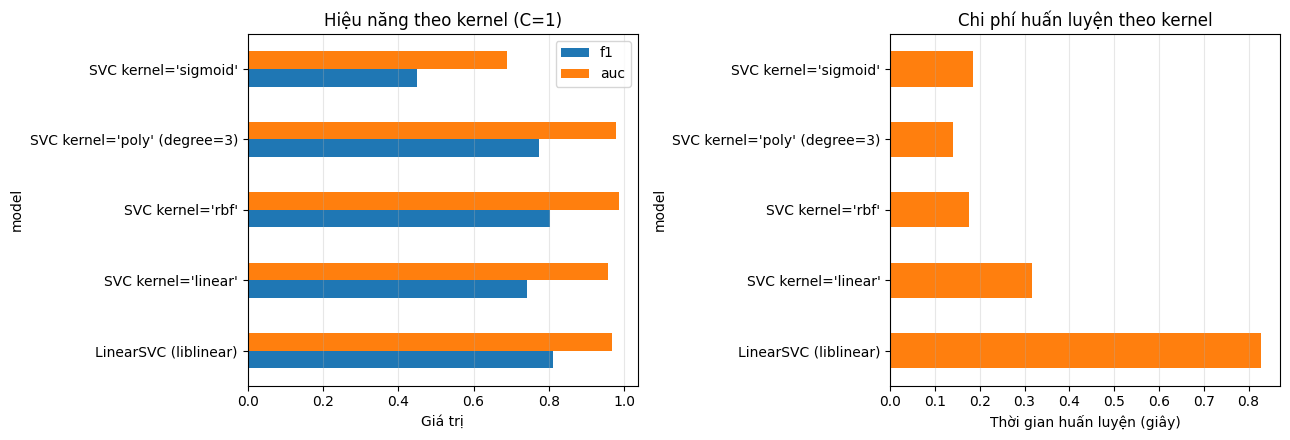

In [5]:
# SVM tìm siêu phẳng phân tách hai lớp sao cho BIÊN (margin) — khoảng cách từ
# siêu phẳng tới các mẫu gần nhất — là lớn nhất. Những mẫu nằm đúng trên biên
# gọi là support vector; chỉ chúng quyết định siêu phẳng, các mẫu còn lại
# không ảnh hưởng gì.
#
# Khi hai lớp không phân tách được bằng một mặt phẳng, SVM dùng KERNEL TRICK:
# thay vì ánh xạ dữ liệu sang không gian nhiều chiều hơn rồi tính ở đó, nó
# chỉ cần tính tích vô hướng trong không gian mới bằng một hàm kernel trên dữ
# liệu gốc. Nhờ đó tránh được chi phí của phép ánh xạ tường minh.
#
#   linear      K(x, z) = xᵀz                     → biên là siêu phẳng
#   rbf         K(x, z) = exp(-gamma‖x - z‖²)     → biên cong, cục bộ
#   poly        K(x, z) = (gamma·xᵀz + r)^degree  → biên đa thức
#   sigmoid     K(x, z) = tanh(gamma·xᵀz + r)     → không phải kernel hợp lệ
#                                                   với mọi tham số
#
# LinearSVC khác SVC(kernel='linear') ở chỗ dùng thuật toán liblinear tối ưu
# riêng cho trường hợp tuyến tính, và tối thiểu hóa squared hinge loss.
rows = []
specs = [
    ("LinearSVC (liblinear)", LinearSVC(C=1.0, max_iter=5000, random_state=SEED)),
    ("SVC kernel='linear'", SVC(max_iter=MAX_ITER, kernel="linear", C=1.0)),
    ("SVC kernel='rbf'", SVC(max_iter=MAX_ITER, kernel="rbf", C=1.0, gamma="scale")),
    ("SVC kernel='poly' (degree=3)", SVC(max_iter=MAX_ITER, kernel="poly", degree=3, C=1.0, gamma="scale")),
    ("SVC kernel='sigmoid'", SVC(max_iter=MAX_ITER, kernel="sigmoid", C=1.0, gamma="scale")),
]
for tag, m in specs:
    t0 = time.perf_counter()
    m.fit(X_g, y_g)                 # dò trên tập con — xem phần A5 để biết lý do
    tf = time.perf_counter() - t0
    r = evaluate(y_te, m.predict(X_te), m.decision_function(X_te), tag)
    r["fit_s"] = tf
    r["n_sv"] = int(m.n_support_.sum()) if hasattr(m, "n_support_") else np.nan
    rows.append(r)

ker_df = pd.DataFrame(rows).set_index("model").round(4)
print(ker_df[["acc", "prec", "rec", "f1", "auc", "fit_s", "n_sv"]])
print(KERNEL_COMMENT)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ker_df[["f1", "auc"]].plot.barh(ax=axes[0])
axes[0].set_xlabel("Giá trị")
axes[0].set_title("Hiệu năng theo kernel (C=1)")
axes[0].grid(axis="x", alpha=.3)

ker_df["fit_s"].plot.barh(ax=axes[1], color="tab:orange")
axes[1].set_xlabel("Thời gian huấn luyện (giây)")
axes[1].set_title("Chi phí huấn luyện theo kernel")
axes[1].grid(axis="x", alpha=.3)
plt.tight_layout()
plt.show()


### A3. Tham Số C – Đánh Đổi Giữa Biên Rộng Và Lỗi Huấn Luyện

           acc    prec     rec      f1     auc  n_sv  sv_ratio
C                                                             
0.01    0.8937  1.0000  0.0034  0.0068  0.9280  1104    0.2208
0.10    0.9418  0.9653  0.4712  0.6333  0.9592   844    0.1688
1.00    0.9644  0.9781  0.6814  0.8032  0.9859   695    0.1390
10.00   0.9854  0.9885  0.8729  0.9271  0.9890   484    0.0968
100.00  0.9864  0.9777  0.8932  0.9336  0.9897   393    0.0786

⚠ Nhận xét: ở C=0,01 mô hình SỤP ĐỔ HOÀN TOÀN — F1 chỉ 0,0068, nghĩa là nó
gần như dự đoán mọi mẫu là bình thường. Với dữ liệu mất cân bằng (10,7% tấn
công), phạt vi phạm biên quá nhẹ khiến cách 'an toàn' nhất là bỏ qua toàn bộ
lớp thiểu số.
Từ đó F1 tăng mạnh theo C: 0,633 (C=0,1) → 0,803 (C=1) → 0,927 (C=10) →
0,934 (C=100). Đây là bộ dữ liệu mà việc chọn C quan trọng nhất trong cả ba
bài — khoảng cách giữa C tệ nhất và C tốt nhất lên tới 0,93 F1.


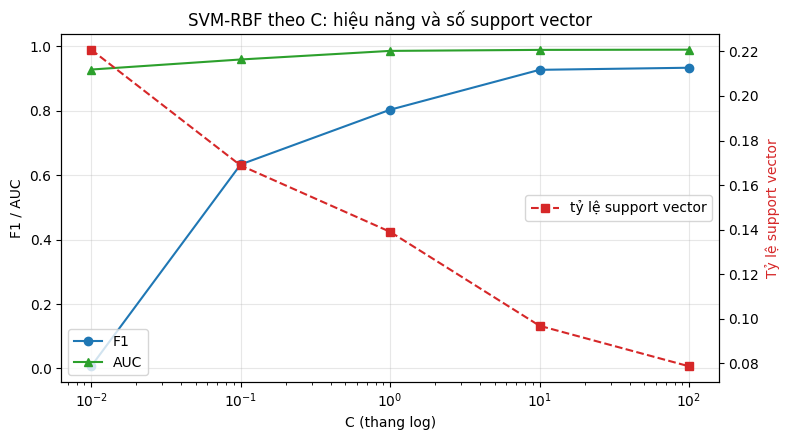

In [6]:
# C là tham số điều chuẩn (regularization), điều khiển đánh đổi giữa:
#   - BIÊN RỘNG (C nhỏ): mô hình chấp nhận nhiều mẫu bị phân loại sai hoặc
#     nằm trong biên, đổi lại biên rộng và mô hình đơn giản → dễ underfit
#   - ÍT LỖI HUẤN LUYỆN (C lớn): mô hình cố phân loại đúng mọi mẫu train,
#     biên hẹp lại và bám sát dữ liệu → dễ overfit
#
# Một dấu hiệu quan sát được: C nhỏ cho NHIỀU support vector hơn, vì biên
# rộng nên nhiều mẫu rơi vào trong biên.
rows = []
for C in C_GRID:
    m = SVC(max_iter=MAX_ITER, kernel="rbf", C=C, gamma="scale").fit(X_g, y_g)
    r = evaluate(y_te, m.predict(X_te), m.decision_function(X_te), C)
    r["n_sv"] = int(m.n_support_.sum())
    r["sv_ratio"] = m.n_support_.sum() / len(y_g)
    rows.append(r)

c_df = pd.DataFrame(rows).set_index("model").round(4)
c_df.index.name = "C"
print(c_df[["acc", "prec", "rec", "f1", "auc", "n_sv", "sv_ratio"]])
print(C_COMMENT)

fig, ax1 = plt.subplots(figsize=(8, 4.5))
ax1.semilogx(c_df.index, c_df["f1"], marker="o", color="tab:blue", label="F1")
ax1.semilogx(c_df.index, c_df["auc"], marker="^", color="tab:green", label="AUC")
ax1.set_xlabel("C (thang log)")
ax1.set_ylabel("F1 / AUC")
ax1.grid(alpha=.3)
ax1.legend(loc="lower left")
ax2 = ax1.twinx()
ax2.semilogx(c_df.index, c_df["sv_ratio"], marker="s", ls="--",
             color="tab:red", label="tỷ lệ support vector")
ax2.set_ylabel("Tỷ lệ support vector", color="tab:red")
ax2.legend(loc="center right")
ax1.set_title("SVM-RBF theo C: hiệu năng và số support vector")
plt.tight_layout()
plt.show()


### A4. Dò Lưới Hai Chiều C × gamma

Dò 5×5 = 25 cấu hình trên tập con 5,000 mẫu — mất 43.6 giây

    C gamma     f1    auc  n_sv
100.0  0.01 0.9346 0.9925   336
100.0 scale 0.9336 0.9897   393
 10.0 scale 0.9271 0.9890   484
100.0   0.1 0.9182 0.9767   744
 10.0   0.1 0.9181 0.9853   807

→ Cấu hình tốt nhất: C = 100, gamma = 0.01  (F1 = 0.9346)

Nhận xét: cấu hình tốt nhất (C=100, gamma=0,01) đạt 0,9346, cải thiện rất
lớn so với 0,8032 của RBF mặc định ở A2. Có ô trong lưới cho F1 bằng ĐÚNG 0 —
mô hình không bắt được một mẫu tấn công nào.
Khoảng F1 trong lưới trải từ 0 tới 0,93: với dữ liệu cảm biến ICS mất cân
bằng, SVM cực kỳ nhạy với siêu tham số, và bỏ qua bước dò lưới đồng nghĩa với
việc có thể nhận một mô hình hoàn toàn vô dụng.


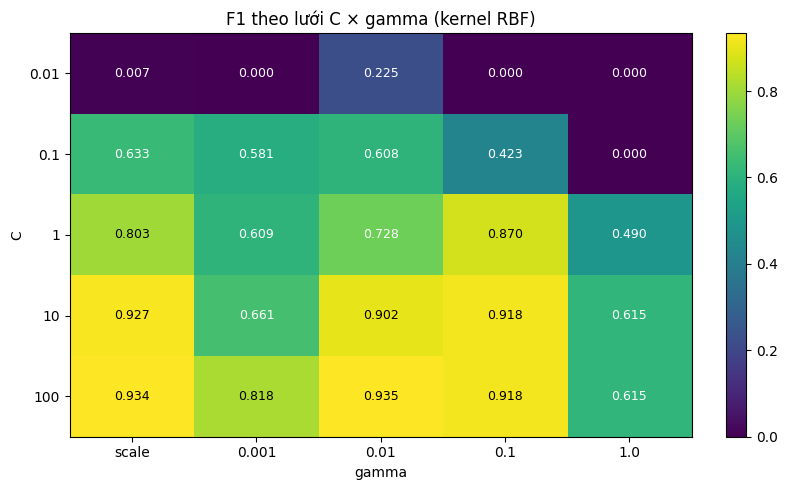

In [7]:
# gamma của kernel RBF điều khiển "bán kính ảnh hưởng" của mỗi support
# vector: K(x, z) = exp(-gamma‖x - z‖²).
#   gamma nhỏ → ảnh hưởng lan rộng, biên quyết định mượt, gần như tuyến tính
#   gamma lớn → ảnh hưởng chỉ quanh từng mẫu, biên cực kỳ gấp khúc, overfit
#
# Mặc định gamma='scale' của sklearn bằng 1 / (số đặc trưng × phương sai của
# dữ liệu). Vì dữ liệu đã chuẩn hóa nên phương sai xấp xỉ 1, tức
# gamma ≈ 1 / số đặc trưng.
#
# C và gamma tương tác với nhau nên phải dò theo LƯỚI HAI CHIỀU, không thể dò
# lần lượt từng tham số.
#
# Việc dò được thực hiện trên TẬP CON X_g (xem phần A5 để biết vì sao): SVM
# đắt theo bình phương số mẫu nên dò lưới trên toàn bộ tập train là không
# khả thi. Mô hình cuối ở phần A8 mới huấn luyện lại trên toàn bộ tập train.
rows = []
t0 = time.perf_counter()
for C in C_GRID:
    for g in GAMMA_GRID:
        m = SVC(max_iter=MAX_ITER, kernel="rbf", C=C, gamma=g).fit(X_g, y_g)
        r = evaluate(y_te, m.predict(X_te), m.decision_function(X_te),
                     f"{C}|{g}")
        r["C"], r["gamma"] = C, str(g)
        r["n_sv"] = int(m.n_support_.sum())
        rows.append(r)
grid_time = time.perf_counter() - t0

grid_df = pd.DataFrame(rows)
print(f"Dò {len(C_GRID)}×{len(GAMMA_GRID)} = {len(rows)} cấu hình trên tập con "
      f"{len(y_g):,} mẫu — mất {grid_time:.1f} giây")
print()
print(grid_df.sort_values("f1", ascending=False)
      .head(5)[["C", "gamma", "f1", "auc", "n_sv"]].round(4).to_string(index=False))

best = grid_df.loc[grid_df["f1"].idxmax()]
C_BEST = float(best["C"])
GAMMA_BEST = best["gamma"] if best["gamma"] == "scale" else float(best["gamma"])
print(f"\n→ Cấu hình tốt nhất: C = {C_BEST:g}, gamma = {best['gamma']}"
      f"  (F1 = {best['f1']:.4f})")
print(GRID_COMMENT)

pivot = grid_df.pivot(index="C", columns="gamma", values="f1")
pivot = pivot[[str(g) for g in GAMMA_GRID]]
fig, ax = plt.subplots(figsize=(8, 5))
im = ax.imshow(pivot.values, cmap="viridis", aspect="auto")
ax.set_xticks(range(len(pivot.columns)), pivot.columns)
ax.set_yticks(range(len(pivot.index)), [f"{c:g}" for c in pivot.index])
ax.set_xlabel("gamma")
ax.set_ylabel("C")
ax.set_title("F1 theo lưới C × gamma (kernel RBF)")
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        v = pivot.values[i, j]
        ax.text(j, i, f"{v:.3f}", ha="center", va="center",
                color="white" if v < pivot.values.max() * 0.85 else "black",
                fontsize=9)
plt.colorbar(im, ax=ax, fraction=.046)
plt.tight_layout()
plt.show()


### A5. Support Vector & Chi Phí Tính Toán

          fit_s  pred_ms_per_sample  n_sv  sv_ratio
n_train                                            
1000     0.0106              0.0093   116    0.1160
2500     0.0437              0.0176   209    0.0836
5000     0.1409              0.0274   336    0.0672
10000    0.4796              0.0391   485    0.0485
12903    0.9053              0.0534   581    0.0450

Độ dốc trên thang log-log: thời gian huấn luyện ≈ n^1.72

Nhận xét: thời gian huấn luyện tăng gần theo bình phương số mẫu, nhưng giá
trị tuyệt đối rất nhỏ (khoảng 1 giây cho toàn bộ 12.903 mẫu). Với hệ SCADA lấy
mẫu theo giờ, chi phí này không phải vấn đề.
Tỷ lệ support vector giảm từ 11,6% xuống 4,5% — mô hình cuối chỉ cần lưu
khoảng 580 trạng thái hệ thống, đủ gọn để triển khai trên thiết bị biên.


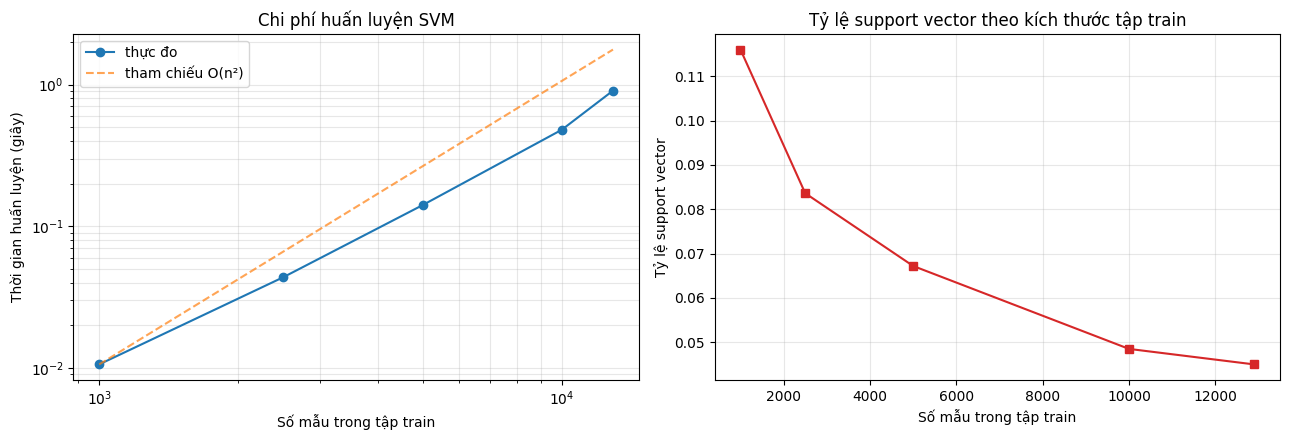

In [8]:
# Huấn luyện SVM đòi hỏi giải một bài toán tối ưu bậc hai có kích thước bằng
# số mẫu. Chi phí thực tế của libsvm nằm giữa O(n²) và O(n³) theo số mẫu —
# đây là lý do SVM không dùng được trực tiếp cho tập dữ liệu hàng triệu mẫu.
#
# Khi dự đoán, chi phí tỷ lệ với SỐ SUPPORT VECTOR chứ không phải số mẫu
# train. Mô hình có ít support vector sẽ vừa nhẹ vừa nhanh.
N_PROBE = 2000
rows = []
for n in [1000, 2500, 5000, 10000, X_tr.shape[0]]:
    if n > X_tr.shape[0]:
        continue
    m = SVC(max_iter=MAX_ITER, kernel="rbf", C=C_BEST, gamma=GAMMA_BEST)
    t0 = time.perf_counter()
    m.fit(X_tr[:n], y_tr[:n])
    tf = time.perf_counter() - t0
    t0 = time.perf_counter()
    m.predict(X_te[:N_PROBE])
    tp = time.perf_counter() - t0
    rows.append({"n_train": n, "fit_s": tf,
                 "pred_ms_per_sample": tp / N_PROBE * 1000,
                 "n_sv": int(m.n_support_.sum()),
                 "sv_ratio": m.n_support_.sum() / n})

cost_df = pd.DataFrame(rows).set_index("n_train").round(4)
print(cost_df)

# Ước lượng số mũ của chi phí: nếu fit_s ∝ n^k thì log(fit_s) là hàm bậc một
# của log(n), và k chính là độ dốc.
k = np.polyfit(np.log(cost_df.index.values.astype(float)),
               np.log(cost_df["fit_s"].values), 1)[0]
print(f"\nĐộ dốc trên thang log-log: thời gian huấn luyện ≈ n^{k:.2f}")
print(COST_COMMENT)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].loglog(cost_df.index, cost_df["fit_s"], marker="o", label="thực đo")
ref = cost_df["fit_s"].iloc[0] * (cost_df.index / cost_df.index[0]) ** 2
axes[0].loglog(cost_df.index, ref, ls="--", alpha=.7, label="tham chiếu O(n²)")
axes[0].set_xlabel("Số mẫu trong tập train")
axes[0].set_ylabel("Thời gian huấn luyện (giây)")
axes[0].set_title("Chi phí huấn luyện SVM")
axes[0].legend()
axes[0].grid(alpha=.3, which="both")

axes[1].plot(cost_df.index, cost_df["sv_ratio"], marker="s", color="tab:red")
axes[1].set_xlabel("Số mẫu trong tập train")
axes[1].set_ylabel("Tỷ lệ support vector")
axes[1].set_title("Tỷ lệ support vector theo kích thước tập train")
axes[1].grid(alpha=.3)
plt.tight_layout()
plt.show()


### A6. Mất Cân Bằng Lớp Với class_weight

Tỷ lệ lớp dương trong tập train: 10.68%

                            acc    prec     rec      f1  f1_macro     auc  \
model                                                                       
class_weight=None        0.9897  0.9963  0.9068  0.9494    0.9718  0.9947   
class_weight='balanced'  0.9834  0.8879  0.9661  0.9253    0.9580  0.9973   

                         n_sv  
model                          
class_weight=None         581  
class_weight='balanced'   961  

Chênh lệch khi bật balanced: Recall +0.0593 | Precision -0.1084 | F1 -0.0241

Nhận xét: đây là bộ dữ liệu DUY NHẤT trong ba bài mà lớp dương (tấn công,
10,7%) thực sự là lớp thiểu số, nên class_weight='balanced' hoạt động đúng
như lý thuyết: Recall tăng mạnh (0,907 → 0,966) nhưng Precision giảm mạnh hơn
(0,996 → 0,888), kết quả F1 thấp hơn.
Lựa chọn phụ thuộc mục tiêu vận hành: nếu bỏ sót một cuộc tấn công vào hệ
thống cấp nước là không thể chấp nhận, thì đánh đổi Precision để lấy Recall
là hợp lý, dù F1 giảm.


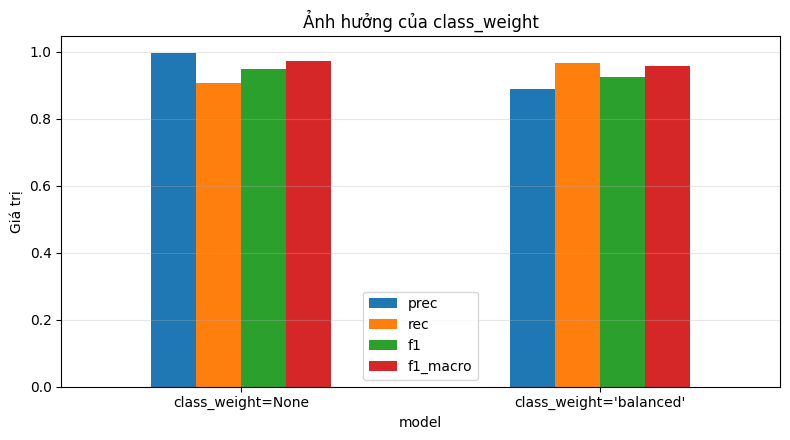

In [9]:
# Dữ liệu mất cân bằng khiến SVM có xu hướng ưu tiên lớp đa số: đẩy siêu
# phẳng về phía lớp thiểu số để giảm tổng lỗi. Tham số class_weight='balanced'
# nhân trọng số của mỗi lớp tỷ lệ nghịch với tần suất, tương đương việc phạt
# nặng hơn khi phân loại sai mẫu thuộc lớp thiểu số.
#
# Lưu ý: đây KHÔNG phải lựa chọn luôn đúng. Nó nâng Recall nhưng thường hạ
# Precision, nên tác động lên F1 có thể theo chiều nào cũng được.
rows = []
for tag, w in [("class_weight=None", None), ("class_weight='balanced'", "balanced")]:
    m = SVC(max_iter=MAX_ITER, kernel="rbf", C=C_BEST, gamma=GAMMA_BEST, class_weight=w).fit(X_tr, y_tr)
    r = evaluate(y_te, m.predict(X_te), m.decision_function(X_te), tag)
    r["n_sv"] = int(m.n_support_.sum())
    rows.append(r)

cw_df = pd.DataFrame(rows).set_index("model").round(4)
print(f"Tỷ lệ lớp dương trong tập train: {y_tr.mean()*100:.2f}%")
print()
print(cw_df[["acc", "prec", "rec", "f1", "f1_macro", "auc", "n_sv"]])
print(f"\nChênh lệch khi bật balanced: Recall {rows[1]['rec'] - rows[0]['rec']:+.4f} | "
      f"Precision {rows[1]['prec'] - rows[0]['prec']:+.4f} | "
      f"F1 {rows[1]['f1'] - rows[0]['f1']:+.4f}")
print(CW_COMMENT)

ax = cw_df[["prec", "rec", "f1", "f1_macro"]].plot.bar(figsize=(8, 4.5), rot=0)
ax.set_ylabel("Giá trị")
ax.set_title("Ảnh hưởng của class_weight")
ax.grid(axis="y", alpha=.3)
plt.tight_layout()
plt.show()


### A7. Xác Suất Từ SVM – Platt Scaling

                                      acc    prec     rec      f1     auc  \
model                                                                       
SVC(probability=True) — Platt      0.9897  0.9963  0.9068  0.9494  0.9947   
CalibratedClassifierCV — isotonic  0.9904  0.9909  0.9186  0.9534  0.9938   

                                    brier   fit_s  
model                                              
SVC(probability=True) — Platt      0.0081  4.5995  
CalibratedClassifierCV — isotonic  0.0084  3.4282  

Thời gian huấn luyện SVM thuần: 0.75s
   probability=True        : 4.60s  → chậm hơn 6.2 lần
   CalibratedClassifierCV  : 3.43s  → chậm hơn 4.6 lần

Nhận xét: Brier score rất thấp (≈0,008) và AUC gần 0,995 — trên tập test
chia ngẫu nhiên, SVM cho cả thứ hạng lẫn xác suất đều tốt. Hãy ghi nhớ con số
này để so với phần A9.
Histogram decision_function cho thấy cụm 'tấn công' nằm sát ngưỡng 0 hơn cụm
'bình thường' — dấu hiệu cho thấy việc dịch ngưỡng có thể giúp ích.


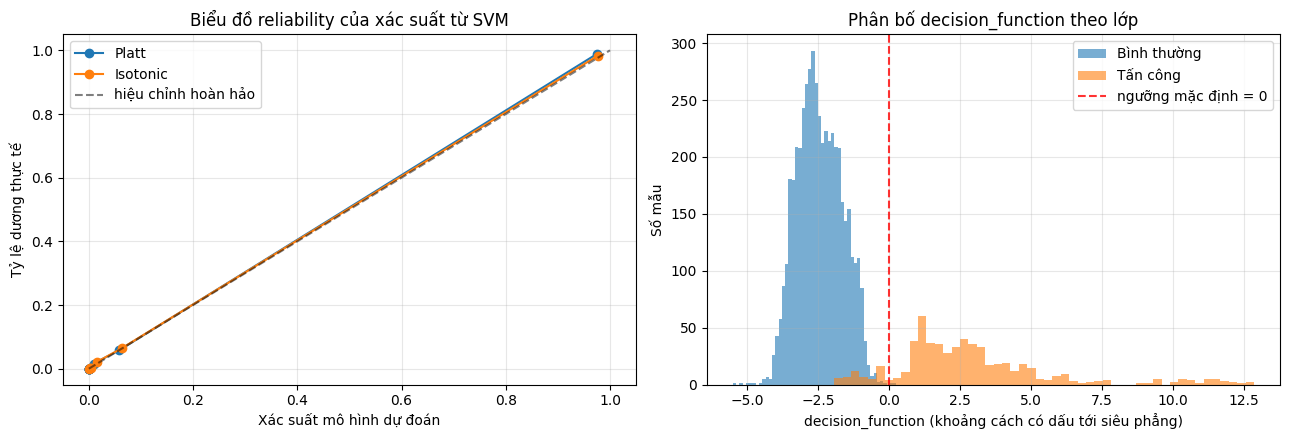

In [10]:
# SVM không phải mô hình xác suất. Để có xác suất, sklearn dùng Platt
# scaling: huấn luyện thêm một hồi quy logistic trên giá trị
# decision_function, với cross-validation nội bộ 5 fold. Hệ quả là
# probability=True làm thời gian huấn luyện tăng nhiều lần.
#
# Ta đo cả chất lượng xác suất (Brier score) lẫn chi phí của hai cách lấy
# xác suất, và so với việc chỉ dùng decision_function thô.
t0 = time.perf_counter()
m_plain = SVC(max_iter=MAX_ITER, kernel="rbf", C=C_BEST, gamma=GAMMA_BEST).fit(X_tr, y_tr)
t_plain = time.perf_counter() - t0

t0 = time.perf_counter()
m_prob = SVC(max_iter=MAX_ITER, kernel="rbf", C=C_BEST, gamma=GAMMA_BEST, probability=True,
             random_state=SEED).fit(X_tr, y_tr)
t_prob = time.perf_counter() - t0
p_platt = m_prob.predict_proba(X_te)[:, 1]

t0 = time.perf_counter()
cal = CalibratedClassifierCV(SVC(max_iter=MAX_ITER, kernel="rbf", C=C_BEST, gamma=GAMMA_BEST),
                             method="isotonic", cv=5).fit(X_tr, y_tr)
t_cal = time.perf_counter() - t0
p_iso = cal.predict_proba(X_te)[:, 1]

rows = [
    dict(evaluate(y_te, m_prob.predict(X_te), p_platt,
                  "SVC(probability=True) — Platt"),
         brier=brier_score_loss(y_te, p_platt), fit_s=t_prob),
    dict(evaluate(y_te, cal.predict(X_te), p_iso,
                  "CalibratedClassifierCV — isotonic"),
         brier=brier_score_loss(y_te, p_iso), fit_s=t_cal),
]
prob_df = pd.DataFrame(rows).set_index("model").round(4)
print(prob_df[["acc", "prec", "rec", "f1", "auc", "brier", "fit_s"]])
print(f"\nThời gian huấn luyện SVM thuần: {t_plain:.2f}s")
print(f"   probability=True        : {t_prob:.2f}s  → chậm hơn {t_prob/t_plain:.1f} lần")
print(f"   CalibratedClassifierCV  : {t_cal:.2f}s  → chậm hơn {t_cal/t_plain:.1f} lần")
print(PROB_COMMENT)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for nm, p in [("Platt", p_platt), ("Isotonic", p_iso)]:
    ft, mp = calibration_curve(y_te, p, n_bins=10, strategy="quantile")
    axes[0].plot(mp, ft, marker="o", label=nm)
axes[0].plot([0, 1], [0, 1], "k--", alpha=.5, label="hiệu chỉnh hoàn hảo")
axes[0].set_xlabel("Xác suất mô hình dự đoán")
axes[0].set_ylabel("Tỷ lệ dương thực tế")
axes[0].set_title("Biểu đồ reliability của xác suất từ SVM")
axes[0].legend()
axes[0].grid(alpha=.3)

d_plain = m_plain.decision_function(X_te)
axes[1].hist(d_plain[y_te == 0], bins=50, alpha=.6, label=TARGET_NAMES[0])
axes[1].hist(d_plain[y_te == 1], bins=50, alpha=.6, label=TARGET_NAMES[1])
axes[1].axvline(0, color="red", ls="--", alpha=.8, label="ngưỡng mặc định = 0")
axes[1].set_xlabel("decision_function (khoảng cách có dấu tới siêu phẳng)")
axes[1].set_ylabel("Số mẫu")
axes[1].set_title("Phân bố decision_function theo lớp")
axes[1].legend()
axes[1].grid(alpha=.3)
plt.tight_layout()
plt.show()


### A8. Chọn Tham Số, Ngưỡng Quyết Định & Mô Hình Cuối

Tách từ tập train: 10,322 mẫu để fit | 2,581 mẫu validation



F1 trên tập validation:
   class_weight=None      : 0.9410
   class_weight=balanced  : 0.9201
→ Chọn class_weight = None



→ Ngưỡng tốt nhất trên validation: -0.2872 (F1 = 0.9495; tại ngưỡng mặc định 0 chỉ đạt 0.9410)



                                   acc    prec     rec      f1  f1_macro  \
model                                                                      
SVM-RBF (ngưỡng mặc định 0)     0.9897  0.9963  0.9068  0.9494    0.9718   
SVM-RBF (C=100, ngưỡng -0.287)  0.9901  0.9890  0.9169  0.9516    0.9730   
Random Forest (200 cây)         0.9919  0.9964  0.9271  0.9605    0.9780   

                                   auc  
model                                   
SVM-RBF (ngưỡng mặc định 0)     0.9947  
SVM-RBF (C=100, ngưỡng -0.287)  0.9947  
Random Forest (200 cây)         0.9978  

Số support vector của mô hình cuối: 581 (4.50% tập train)
Thời gian huấn luyện: SVM 0.80s | Random Forest 2.00s

Confusion matrix SVM:  TN=4934  FP=6  FN=49  TP=541
  FP = 6 cảnh báo giả | FN = 49 lần bỏ sót tấn công

              precision    recall  f1-score   support

 Bình thường     0.9902    0.9988    0.9945      4940
    Tấn công     0.9890    0.9169    0.9516       590

    accuracy                  

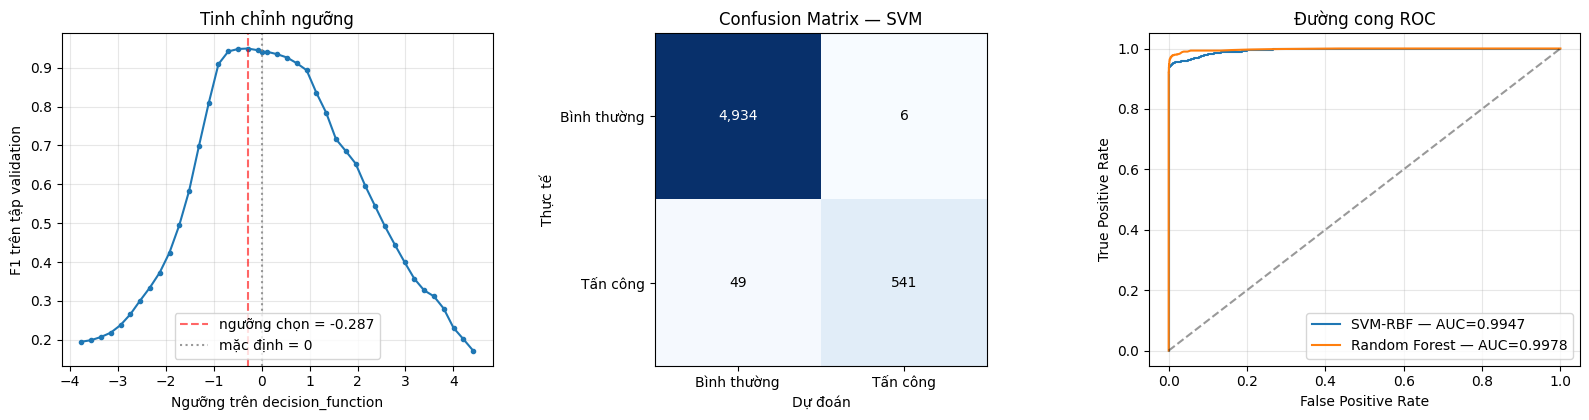

In [11]:
# Hai quyết định còn lại — có bật class_weight hay không, và chọn ngưỡng trên
# decision_function — phải đưa ra trên tập validation tách từ train, KHÔNG
# được dùng tập test.
#
# Với SVM, ngưỡng mặc định là 0 (nằm đúng trên siêu phẳng) chứ không phải 0,5
# như các mô hình xác suất.
X_a, X_v, y_a, y_v = train_test_split(X_tr, y_tr, test_size=0.2,
                                      random_state=SEED, stratify=y_tr)
print(f"Tách từ tập train: {X_a.shape[0]:,} mẫu để fit | "
      f"{X_v.shape[0]:,} mẫu validation")

pick = {}
for tag, w in [("None", None), ("balanced", "balanced")]:
    m = SVC(max_iter=MAX_ITER, kernel="rbf", C=C_BEST, gamma=GAMMA_BEST, class_weight=w).fit(X_a, y_a)
    pick[tag] = f1_score(y_v, m.predict(X_v), zero_division=0)
print("\nF1 trên tập validation:")
for k_, v in pick.items():
    print(f"   class_weight={k_:10s}: {v:.4f}")
CW = "balanced" if pick["balanced"] > pick["None"] else None
print(f"→ Chọn class_weight = {CW}")

m_val = SVC(max_iter=MAX_ITER, kernel="rbf", C=C_BEST, gamma=GAMMA_BEST, class_weight=CW).fit(X_a, y_a)
d_val = m_val.decision_function(X_v)
# Quét ngưỡng trong khoảng giá trị thực tế của decision_function trên
# validation, bỏ 1% hai đầu để tránh các giá trị ngoại lai.
lo, hi = np.percentile(d_val, 1), np.percentile(d_val, 99)
# Đưa cả giá trị 0 — ngưỡng mặc định của SVM — vào lưới. Nếu không, ngưỡng
# "tốt nhất" tìm được trên validation có thể còn kém hơn ngưỡng mặc định,
# chỉ vì 0 không nằm trong các điểm được quét.
THR_GRID = np.unique(np.concatenate([np.linspace(lo, hi, 41), [0.0]]))
f1_by_thr = [f1_score(y_v, (d_val >= t).astype(int), zero_division=0)
             for t in THR_GRID]
THR = float(THR_GRID[int(np.argmax(f1_by_thr))])
print(f"\n→ Ngưỡng tốt nhất trên validation: {THR:+.4f} "
      f"(F1 = {max(f1_by_thr):.4f}; tại ngưỡng mặc định 0 chỉ đạt "
      f"{f1_score(y_v, (d_val >= 0).astype(int), zero_division=0):.4f})")

# ── Mô hình cuối, huấn luyện lại trên toàn bộ tập train ────────────────────
final = SVC(max_iter=MAX_ITER, kernel="rbf", C=C_BEST, gamma=GAMMA_BEST, class_weight=CW)
final.fit(X_tr, y_tr)
d_te = final.decision_function(X_te)
y_pred = (d_te >= THR).astype(int)

svm_res = evaluate(y_te, y_pred, d_te,
                   f"SVM-RBF (C={C_BEST:g}, ngưỡng {THR:+.3f})")
svm_res_0 = evaluate(y_te, (d_te >= 0).astype(int), d_te,
                     "SVM-RBF (ngưỡng mặc định 0)")

t0 = time.perf_counter()
SVC(max_iter=MAX_ITER, kernel="rbf", C=C_BEST, gamma=GAMMA_BEST, class_weight=CW).fit(X_tr, y_tr)
t_svm = time.perf_counter() - t0

rf = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1)
t0 = time.perf_counter()
rf.fit(X_tr, y_tr)
t_rf = time.perf_counter() - t0
rf_score = rf.predict_proba(X_te)[:, 1]
rf_res = evaluate(y_te, rf.predict(X_te), rf_score, "Random Forest (200 cây)")

cmp_df = pd.DataFrame([svm_res_0, svm_res, rf_res]).set_index("model").round(4)
print()
print(cmp_df[["acc", "prec", "rec", "f1", "f1_macro", "auc"]])
print(f"\nSố support vector của mô hình cuối: {final.n_support_.sum():,} "
      f"({final.n_support_.sum()/len(y_tr)*100:.2f}% tập train)")
print(f"Thời gian huấn luyện: SVM {t_svm:.2f}s | Random Forest {t_rf:.2f}s")

cm = confusion_matrix(y_te, y_pred)
tn, fp, fn, tp = cm.ravel()
print(f"\nConfusion matrix SVM:  TN={tn}  FP={fp}  FN={fn}  TP={tp}")
print(f"  FP = {fp} cảnh báo giả | FN = {fn} lần bỏ sót {TARGET_NAMES[1].lower()}")
print("\n" + classification_report(y_te, y_pred, target_names=TARGET_NAMES,
                                    digits=4))
print(FINAL_COMMENT)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
axes[0].plot(THR_GRID, f1_by_thr, marker="o", ms=3)
axes[0].axvline(THR, color="red", ls="--", alpha=.6, label=f"ngưỡng chọn = {THR:+.3f}")
axes[0].axvline(0, color="gray", ls=":", alpha=.8, label="mặc định = 0")
axes[0].set_xlabel("Ngưỡng trên decision_function")
axes[0].set_ylabel("F1 trên tập validation")
axes[0].set_title("Tinh chỉnh ngưỡng")
axes[0].legend()
axes[0].grid(alpha=.3)

axes[1].imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm):
    axes[1].text(j, i, f"{v:,}", ha="center", va="center",
                 color="white" if v > cm.max() / 2 else "black")
axes[1].set_xticks([0, 1], TARGET_NAMES)
axes[1].set_yticks([0, 1], TARGET_NAMES)
axes[1].set_xlabel("Dự đoán")
axes[1].set_ylabel("Thực tế")
axes[1].set_title("Confusion Matrix — SVM")

for nm, sc in [("SVM-RBF", d_te), ("Random Forest", rf_score)]:
    fpr, tpr, _ = roc_curve(y_te, sc)
    axes[2].plot(fpr, tpr, label=f"{nm} — AUC={roc_auc_score(y_te, sc):.4f}")
axes[2].plot([0, 1], [0, 1], "k--", alpha=.4)
axes[2].set_xlabel("False Positive Rate")
axes[2].set_ylabel("True Positive Rate")
axes[2].set_title("Đường cong ROC")
axes[2].legend()
axes[2].grid(alpha=.3)
plt.tight_layout()
plt.show()


### A9. Đánh Giá Trên Tập Held-Out (test_dataset_2)

Tập held-out sau chuẩn hóa: (10081, 37)



                                      acc    prec     rec      f1  f1_macro  \
model                                                                         
SVM-RBF (C=100, ngưỡng -0.287)     0.9901  0.9890  0.9169  0.9516    0.9730   
SVM — Test 2 (held-out)            0.8854  0.9171  0.3194  0.4738    0.7048   
Random Forest (200 cây)            0.9919  0.9964  0.9271  0.9605    0.9780   
Random Forest — Test 2 (held-out)  0.8856  0.9760  0.2991  0.4579    0.6970   

                                      auc  
model                                      
SVM-RBF (C=100, ngưỡng -0.287)     0.9947  
SVM — Test 2 (held-out)            0.7323  
Random Forest (200 cây)            0.9978  
Random Forest — Test 2 (held-out)  0.8762  

Confusion matrix trên Test 2:  TN=8406  FP=47  FN=1108  TP=520

→ F1 tụt từ 0.9516 (test ngẫu nhiên) xuống 0.4738 (held-out thật)
→ Recall còn 0.3194: bỏ sót 1,108/1,628 mẫu tấn công
→ Random Forest trên cùng tập đó: F1 = 0.4579, AUC = 0.8762

═══════════════

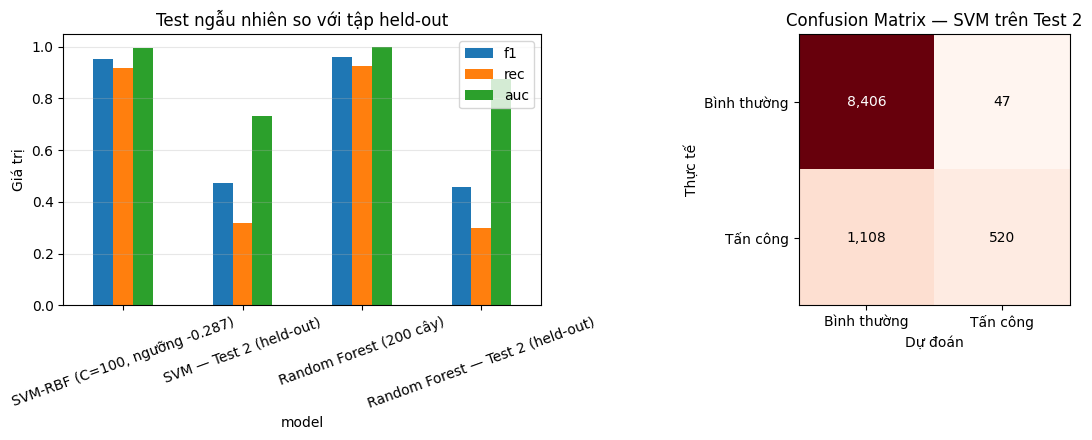

In [12]:
# Giống Bài 6 (KNN) và Bài 7 (Naive Bayes), tập test ở A8 được tách NGẪU
# NHIÊN từ cùng chuỗi thời gian với tập train nên bị rò rỉ thời gian.
# test_dataset_2 thuộc một giai đoạn tấn công hoàn toàn khác.
X_ho = scaler.transform(X_ho_raw.values)
print(f"Tập held-out sau chuẩn hóa: {X_ho.shape}")

d_ho = final.decision_function(X_ho)
yp_ho = (d_ho >= THR).astype(int)
ho_res = evaluate(y_ho, yp_ho, d_ho, "SVM — Test 2 (held-out)")
rf_ho_score = rf.predict_proba(X_ho)[:, 1]
rf_ho = evaluate(y_ho, rf.predict(X_ho), rf_ho_score,
                 "Random Forest — Test 2 (held-out)")

ho_df = pd.DataFrame([svm_res, ho_res, rf_res, rf_ho]).set_index("model").round(4)
print()
print(ho_df[["acc", "prec", "rec", "f1", "f1_macro", "auc"]])

cm_ho = confusion_matrix(y_ho, yp_ho)
tn2, fp2, fn2, tp2 = cm_ho.ravel()
print(f"\nConfusion matrix trên Test 2:  TN={tn2}  FP={fp2}  FN={fn2}  TP={tp2}")
print(f"\n→ F1 tụt từ {svm_res['f1']:.4f} (test ngẫu nhiên) xuống "
      f"{ho_res['f1']:.4f} (held-out thật)")
print(f"→ Recall còn {ho_res['rec']:.4f}: bỏ sót {fn2:,}/{int(y_ho.sum()):,} "
      f"mẫu tấn công")
print(f"→ Random Forest trên cùng tập đó: F1 = {rf_ho['f1']:.4f}, "
      f"AUC = {rf_ho['auc']:.4f}")
print(HELDOUT_COMMENT)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ho_df[["f1", "rec", "auc"]].plot.bar(ax=axes[0], rot=20)
axes[0].set_title("Test ngẫu nhiên so với tập held-out")
axes[0].set_ylabel("Giá trị")
axes[0].grid(axis="y", alpha=.3)

axes[1].imshow(cm_ho, cmap="Reds")
for (i, j), v in np.ndenumerate(cm_ho):
    axes[1].text(j, i, f"{v:,}", ha="center", va="center",
                 color="white" if v > cm_ho.max() / 2 else "black")
axes[1].set_xticks([0, 1], TARGET_NAMES)
axes[1].set_yticks([0, 1], TARGET_NAMES)
axes[1].set_xlabel("Dự đoán")
axes[1].set_ylabel("Thực tế")
axes[1].set_title("Confusion Matrix — SVM trên Test 2")
plt.tight_layout()
plt.show()


---
## Nhận Xét & Câu Hỏi Thảo Luận

**Tổng hợp những gì bài thực hành cho thấy**

1. Ở `C=1` mọi kernel chỉ đạt F1 quanh 0,74–0,81 — nhưng đó là vì `C` quá nhỏ, không phải vì kernel kém.
2. Ở `C=0,01` mô hình sụp đổ hoàn toàn (F1 = 0,0068): nó gần như dự đoán mọi mẫu là bình thường. Với dữ liệu mất cân bằng, phạt quá nhẹ khiến bỏ qua lớp thiểu số trở thành cách "an toàn" nhất.
3. Dò lưới nâng F1 từ 0,8032 lên 0,9346. Khoảng F1 trong lưới trải từ **0** tới 0,93 — đây là bộ dữ liệu nhạy với siêu tham số nhất trong ba bài.
4. Đây là bộ dữ liệu duy nhất mà lớp dương thực sự là thiểu số (10,7%), nên `class_weight='balanced'` hoạt động đúng lý thuyết: Recall tăng 0,907 → 0,966, Precision giảm 0,996 → 0,888.
5. Trên tập test chia ngẫu nhiên: SVM 0,9516, ngang KNN (0,9521), vượt xa Naive Bayes (0,6316).
6. Trên tập held-out: SVM 0,4738 — **tốt nhất trong ba thuật toán** và nhích hơn cả Random Forest (0,4579). Nhưng Recall chỉ 0,3194.

**Câu hỏi thảo luận**

1. Ở `C=0,01` mô hình cho F1 = 0,0068. Hãy giải thích cơ chế dẫn tới kết quả đó, dựa trên tỷ lệ 10,7% mẫu tấn công và ý nghĩa của tham số `C`.
2. Có ô trong lưới `C × gamma` cho F1 bằng đúng 0. Điều này có nghĩa gì về dự đoán của mô hình, và vì sao Accuracy của chính mô hình đó vẫn khoảng 89%?
3. `class_weight='balanced'` làm F1 giảm nhưng Recall tăng rõ. Với hệ thống cấp nước, bạn sẽ chọn cấu hình nào và căn cứ vào đâu? Hãy lập luận bằng hậu quả vận hành thay vì bằng chỉ số.
4. SVM tổng quát hóa sang tập held-out tốt hơn KNN (0,4738 so với 0,3558) và Naive Bayes (0,1606). Hãy giải thích vì sao, dựa trên việc SVM chỉ giữ lại các support vector nằm trên biên.
5. SVM trên held-out còn nhích hơn Random Forest về F1 (0,4738 so với 0,4579) nhưng AUC lại thấp hơn rõ (0,7323 so với 0,8762). Hai chỉ số nói hai điều khác nhau — hãy giải thích và cho biết trong vận hành SOC thì chỉ số nào quan trọng hơn.
6. Recall trên held-out chỉ 0,3194 dù đây là mô hình tốt nhất trong ba bài. Điều đó cho thấy vấn đề nằm ở đâu, và cần thay đổi gì trong thiết kế thực nghiệm trước khi tin vào bất kỳ con số nào?
7. Sau ba bài KNN, Naive Bayes và SVM trên cùng bộ BATADAL, hãy viết lại quy trình thực nghiệm mà bạn cho là đúng cho dữ liệu chuỗi thời gian của hệ thống ICS, nêu rõ cách chia dữ liệu và cách chọn siêu tham số.
